**Interacting with Web APIs
Problem Statement: Analyzing Weather Data from OpenWeatherMap API
Dataset: Weather data retrieved from OpenWeatherMap API
Description: The goal is to interact with the OpenWeatherMap API to retrieve weather data
for a specific location and perform data modeling and visualization to analyze weather
patterns over time.
Tasks to Perform:
1. Register and obtain API key from OpenWeatherMap.
2. Interact with the OpenWeatherMap API using the API key to retrieve weather data for
a specific location.
3. Extract relevant weather attributes such as temperature, humidity, wind speed, and
precipitation from the API response.
4. Clean and preprocess the retrieved data, handling missing values or inconsistent
formats.
5. Perform data modeling to analyze weather patterns, such as calculating average
temperature, maximum/minimum values, or trends over time.
6. Visualize the weather data using appropriate plots, such as line charts, bar plots, or
scatter plots, to represent temperature changes, precipitation levels, or wind speed
variations.
7. Apply data aggregation techniques to summarize weather statistics by specific time
periods (e.g., daily, monthly, seasonal).
8. Incorporate geographical information, if available, to create maps or geospatial
visualizations representing weather patterns across different locations.
9. Explore and visualize relationships between weather attributes, such as temperature
and humidity, using correlation plots or heatmaps.**

In [1]:
!pip install requests pandas numpy matplotlib seaborn

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.5.2-cp314-cp314-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached charset_normalizer-3.5.2-cp314-cp314-win_amd64.whl (210 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
Using cached urllib3-2.8.0-py3-none-any.whl (135 kB)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)

   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   -------- ------------------------------- 1/5 [idna]
   ---------------- ----------------------- 2/5 [charset_normalizer]
   -------------------------------- ------- 4/5 [requests]
   ---------------------------------------- 5/5 [requests]



In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [11]:
API_KEY = "77c0a521a891bc3101389fa52a503806"
CITY = "Pune"

In [12]:
url = "https://api.openweathermap.org/data/2.5/weather"

params = {
    'q': CITY,
    'appid': API_KEY,
    'units': 'metric'
}

response = requests.get(url, params=params)

print("Status Code:", response.status_code)

Status Code: 200


In [13]:
if response.status_code == 200:
    weather_data = response.json()
    print(weather_data)
else:
    print("Error:", response.status_code)
    print(response.text)

{'coord': {'lon': 73.8553, 'lat': 18.5196}, 'weather': [{'id': 802, 'main': 'Clouds', 'description': 'scattered clouds', 'icon': '03n'}], 'base': 'stations', 'main': {'temp': 28.23, 'feels_like': 28.26, 'temp_min': 28.23, 'temp_max': 28.23, 'pressure': 1013, 'humidity': 45, 'sea_level': 1013, 'grnd_level': 941}, 'visibility': 10000, 'wind': {'speed': 3.77, 'deg': 272, 'gust': 4.71}, 'clouds': {'all': 26}, 'dt': 1793364681, 'sys': {'country': 'IN', 'sunrise': 1793322196, 'sunset': 1793363584}, 'timezone': 19800, 'id': 1259229, 'name': 'Pune', 'cod': 200}


In [14]:
forecast_url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    'q': CITY,
    'appid': API_KEY,
    'units': 'metric'
}

response = requests.get(forecast_url, params=params)

if response.status_code == 200:
    forecast_data = response.json()
    print("Weather forecast retrieved successfully!")
else:
    print("Error:", response.status_code)
    print(response.text)

Weather forecast retrieved successfully!


In [16]:
print(forecast_data.keys())

print("\nCity Information:")
print(forecast_data['city'])

print("\nFirst Forecast Record:")
print(forecast_data['list'][0])

dict_keys(['cod', 'message', 'cnt', 'list', 'city'])

City Information:
{'id': 1259229, 'name': 'Pune', 'coord': {'lat': 18.5196, 'lon': 73.8553}, 'country': 'IN', 'population': 9999, 'timezone': 19800, 'sunrise': 1793322196, 'sunset': 1793363584}

First Forecast Record:
{'dt': 1793372400, 'main': {'temp': 29.08, 'feels_like': 29.18, 'temp_min': 26.85, 'temp_max': 29.08, 'pressure': 1013, 'sea_level': 1013, 'grnd_level': 942, 'humidity': 45, 'temp_kf': 2.23, 'dew_point': 15.95}, 'weather': [{'id': 803, 'main': 'Clouds', 'description': 'broken clouds', 'icon': '04n'}], 'clouds': {'all': 63}, 'wind': {'speed': 2.78, 'deg': 251, 'gust': 4.22}, 'visibility': 10000, 'pop': 0.25, 'sys': {'pod': 'n'}, 'dt_txt': '2026-10-30 15:00:00'}


In [17]:
weather_list = []

for item in forecast_data['list']:

    weather_list.append({
        'Date': item['dt_txt'],
        'Temperature': item['main']['temp'],
        'Humidity': item['main']['humidity'],
        'Wind_Speed': item['wind']['speed'],
        'Precipitation': item.get('rain', {}).get('3h', 0),
        'Weather': item['weather'][0]['description']
    })

df = pd.DataFrame(weather_list)

df.head()

,Date,Temperature,Humidity,Wind_Speed,Precipitation,Weather
0,2026-10-30 15:00:00,29.08,45,2.78,0.00,broken clouds
1,2026-10-30 18:00:00,27.00,66,2.42,0.57,light rain
2,2026-10-30 21:00:00,25.98,79,1.47,0.33,light rain
3,2026-10-31 00:00:00,22.78,77,1.34,0.00,scattered clouds
4,2026-10-31 03:00:00,27.12,65,1.31,0.00,broken clouds


In [18]:
df.head()

,Date,Temperature,Humidity,Wind_Speed,Precipitation,Weather
0,2026-10-30 15:00:00,29.08,45,2.78,0.00,broken clouds
1,2026-10-30 18:00:00,27.00,66,2.42,0.57,light rain
2,2026-10-30 21:00:00,25.98,79,1.47,0.33,light rain
3,2026-10-31 00:00:00,22.78,77,1.34,0.00,scattered clouds
4,2026-10-31 03:00:00,27.12,65,1.31,0.00,broken clouds


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           40 non-null     str    
 1   Temperature    40 non-null     float64
 2   Humidity       40 non-null     int64  
 3   Wind_Speed     40 non-null     float64
 4   Precipitation  40 non-null     float64
 5   Weather        40 non-null     str    
dtypes: float64(3), int64(1), str(2)
memory usage: 2.0 KB


In [20]:
print(df.isnull().sum())

Date             0
Temperature      0
Humidity         0
Wind_Speed       0
Precipitation    0
Weather          0
dtype: int64


In [21]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [22]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 40
Columns: 6


In [23]:
#data cleaning and processing
df['Date'] = pd.to_datetime(df['Date'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           40 non-null     datetime64[us]
 1   Temperature    40 non-null     float64       
 2   Humidity       40 non-null     int64         
 3   Wind_Speed     40 non-null     float64       
 4   Precipitation  40 non-null     float64       
 5   Weather        40 non-null     str           
dtypes: datetime64[us](1), float64(3), int64(1), str(1)
memory usage: 2.0 KB


In [24]:
df['Temperature'] = df['Temperature'].fillna(
    df['Temperature'].mean()
)

df['Humidity'] = df['Humidity'].fillna(
    df['Humidity'].mean()
)

df['Wind_Speed'] = df['Wind_Speed'].fillna(
    df['Wind_Speed'].mean()
)

df['Precipitation'] = df['Precipitation'].fillna(0)

In [25]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


In [26]:
#verify cleaned dataset

print(df.isnull().sum())

df.head()

Date             0
Temperature      0
Humidity         0
Wind_Speed       0
Precipitation    0
Weather          0
dtype: int64


,Date,Temperature,Humidity,Wind_Speed,Precipitation,Weather
0,2026-10-30 15:00:00,29.08,45,2.78,0.00,broken clouds
1,2026-10-30 18:00:00,27.00,66,2.42,0.57,light rain
2,2026-10-30 21:00:00,25.98,79,1.47,0.33,light rain
3,2026-10-31 00:00:00,22.78,77,1.34,0.00,scattered clouds
4,2026-10-31 03:00:00,27.12,65,1.31,0.00,broken clouds


In [27]:
#performing data modeling
avg_temp = df['Temperature'].mean()

print("Average Temperature:", round(avg_temp, 2), "°C")

Average Temperature: 26.67 °C


In [28]:
max_temp = df['Temperature'].max()

min_temp = df['Temperature'].min()

print("Maximum Temperature:", max_temp, "°C")

print("Minimum Temperature:", min_temp, "°C")

Maximum Temperature: 34.66 °C
Minimum Temperature: 22.5 °C


In [29]:
avg_humidity = df['Humidity'].mean()

print("Average Humidity:", round(avg_humidity, 2), "%")

Average Humidity: 63.72 %


In [30]:
avg_wind = df['Wind_Speed'].mean()

print("Average Wind Speed:", round(avg_wind, 2), "m/s")

Average Wind Speed: 2.2 m/s


In [31]:
total_rain = df['Precipitation'].sum()

print("Total Forecast Precipitation:", total_rain, "mm")

Total Forecast Precipitation: 15.39 mm


In [32]:
#data aggregation
df['Day'] = df['Date'].dt.date

daily_weather = df.groupby('Day').agg({
    'Temperature': 'mean',
    'Humidity': 'mean',
    'Wind_Speed': 'mean',
    'Precipitation': 'sum'
})

daily_weather

,Temperature,Humidity,Wind_Speed,Precipitation
Day,,,,
2026-10-30,27.353333,63.333333,2.223333,0.90
2026-10-31,28.307500,61.375000,1.966250,0.69
2026-11-01,25.390000,67.625000,1.727500,4.73
2026-11-02,25.320000,69.875000,2.418750,7.71
2026-11-03,26.823750,60.375000,2.191250,1.13
2026-11-04,27.588000,57.000000,2.970000,0.23


In [33]:
daily_temp = df.groupby('Day')['Temperature'].agg(
    ['min', 'max', 'mean']
)

daily_temp

,min,max,mean
Day,,,
2026-10-30,25.98,29.08,27.353333
2026-10-31,22.78,34.66,28.307500
2026-11-01,22.53,30.11,25.390000
2026-11-02,22.50,30.47,25.320000
2026-11-03,23.45,30.74,26.823750
2026-11-04,22.72,31.35,27.588000


In [34]:
df['Month'] = df['Date'].dt.month_name()

monthly_weather = df.groupby('Month').agg({
    'Temperature': 'mean',
    'Humidity': 'mean',
    'Wind_Speed': 'mean'
})

monthly_weather

,Temperature,Humidity,Wind_Speed
Month,,,
November,26.145172,64.413793,2.260345
October,28.047273,61.909091,2.036364


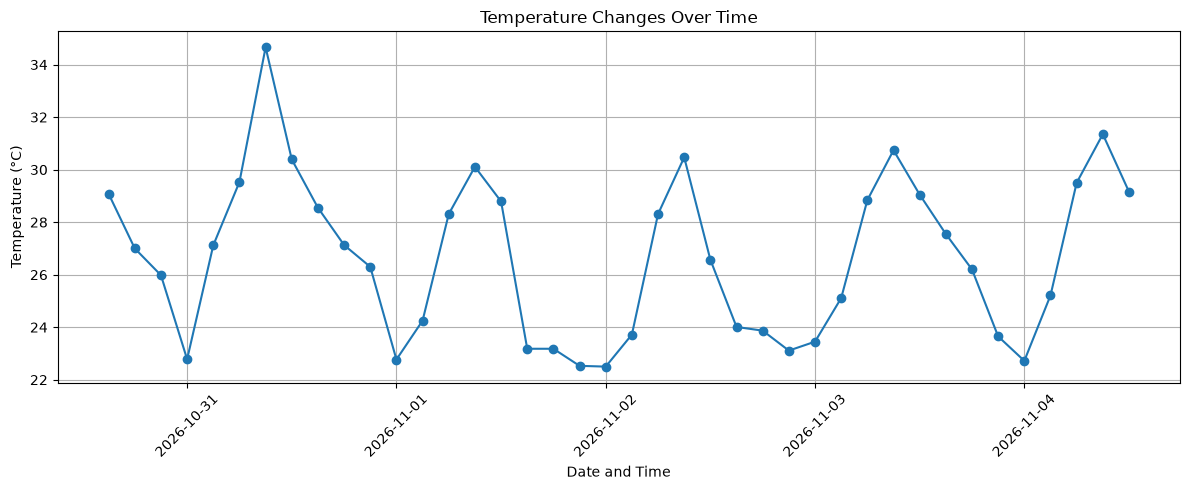

In [35]:
#weather data visualization
#tempreature changes over time (Line Chart)
plt.figure(figsize=(12, 5))

plt.plot(
    df['Date'],
    
    df['Temperature'],
    marker='o'
)

plt.title('Temperature Changes Over Time')
plt.xlabel('Date and Time')
plt.ylabel('Temperature (°C)')

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

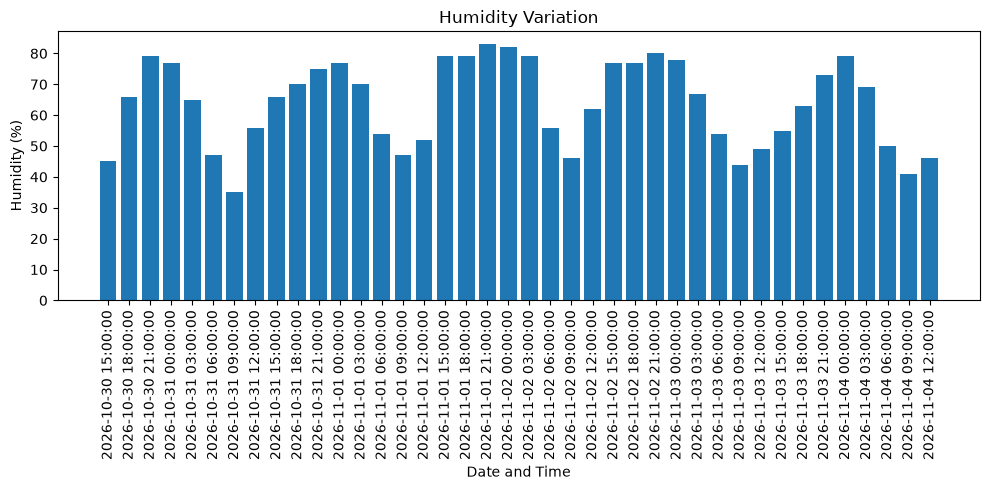

In [36]:
#humidity visualization(bar chart)
plt.figure(figsize=(10, 5))

plt.bar(
    df['Date'].astype(str),
    df['Humidity']
)

plt.title('Humidity Variation')
plt.xlabel('Date and Time')
plt.ylabel('Humidity (%)')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

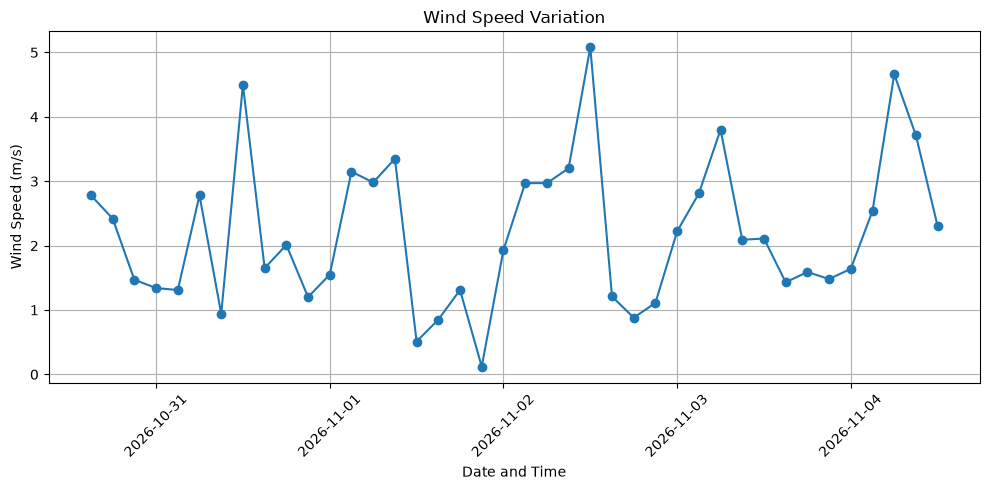

In [37]:
#wind speed visualization
plt.figure(figsize=(10, 5))

plt.plot(
    df['Date'],
    df['Wind_Speed'],
    marker='o'
)

plt.title('Wind Speed Variation')
plt.xlabel('Date and Time')
plt.ylabel('Wind Speed (m/s)')

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

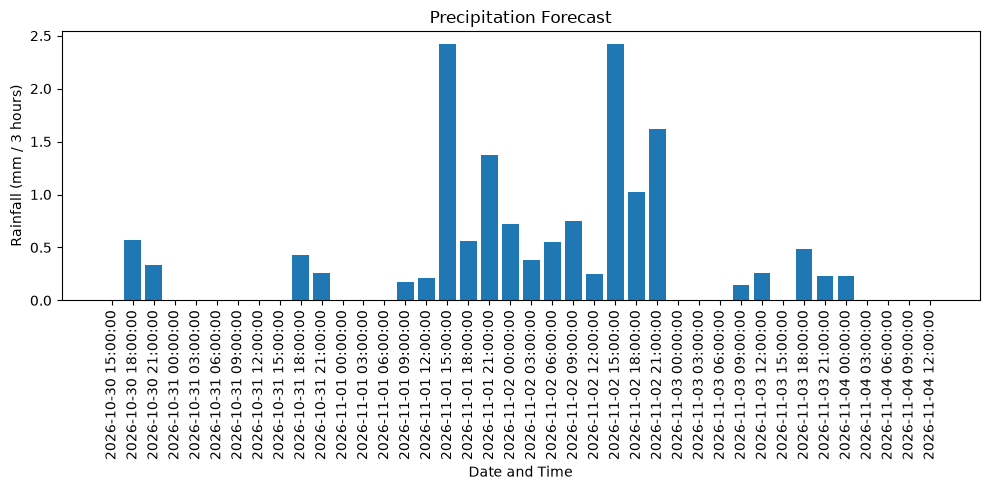

In [38]:
#precipitation visualization
plt.figure(figsize=(10, 5))

plt.bar(
    df['Date'].astype(str),
    df['Precipitation']
)

plt.title('Precipitation Forecast')
plt.xlabel('Date and Time')
plt.ylabel('Rainfall (mm / 3 hours)')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

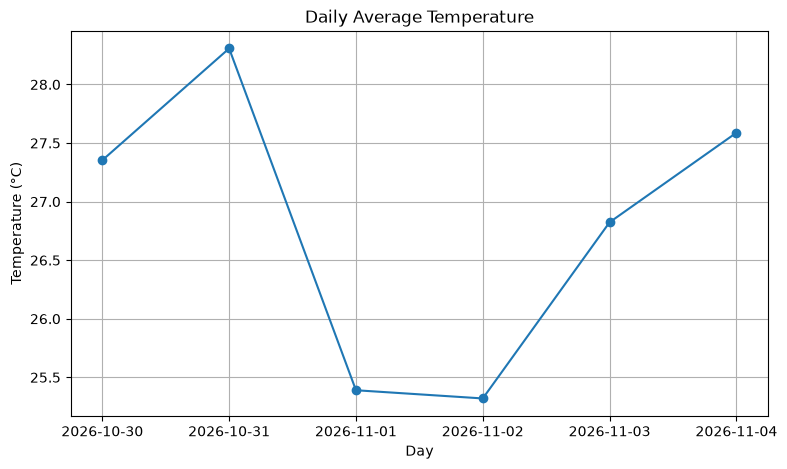

In [39]:
#daily avg temp
plt.figure(figsize=(9, 5))

plt.plot(
    daily_weather.index.astype(str),
    daily_weather['Temperature'],
    marker='o'
)

plt.title('Daily Average Temperature')
plt.xlabel('Day')
plt.ylabel('Temperature (°C)')

plt.grid()
plt.show()

In [40]:
#Geographical Visualization
latitude = forecast_data['city']['coord']['lat']

longitude = forecast_data['city']['coord']['lon']

print("Latitude:", latitude)
print("Longitude:", longitude)

Latitude: 18.5196
Longitude: 73.8553


In [41]:
!pip install folium

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)

   ---------------- ----------------------- 2/5 [jinja2]
   ---------------- ----------------------- 2/5 [jinja2]
   ---------------- ----------------------- 2/5 [jinja2]
   ---------------- ----------------------- 2/5 [jinja2]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   ---------------------------------------- 5/5 [folium]



In [42]:
import folium

weather_map = folium.Map(
    location=[latitude, longitude],
    zoom_start=10
)

folium.Marker(
    [latitude, longitude],
    popup=CITY,
    tooltip="Weather Location"
).add_to(weather_map)

weather_map

In [43]:
#correlation analysis
correlation = df[
    ['Temperature', 'Humidity', 'Wind_Speed', 'Precipitation']
].corr()

print(correlation)

               Temperature  Humidity  Wind_Speed  Precipitation
Temperature       1.000000 -0.941605    0.406432      -0.425810
Humidity         -0.941605  1.000000   -0.445598       0.453611
Wind_Speed        0.406432 -0.445598    1.000000      -0.415841
Precipitation    -0.425810  0.453611   -0.415841       1.000000


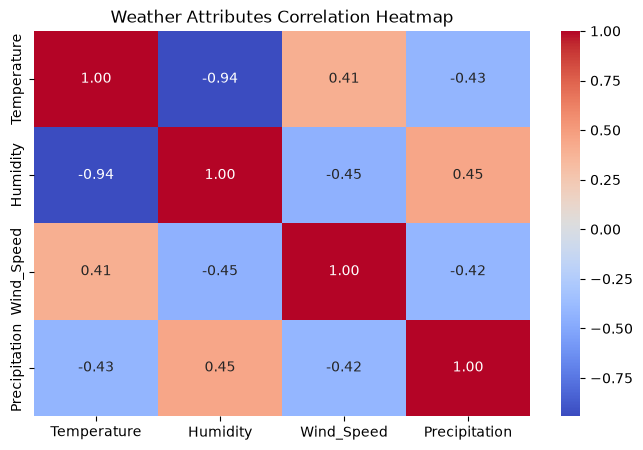

In [44]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Weather Attributes Correlation Heatmap')

plt.show()

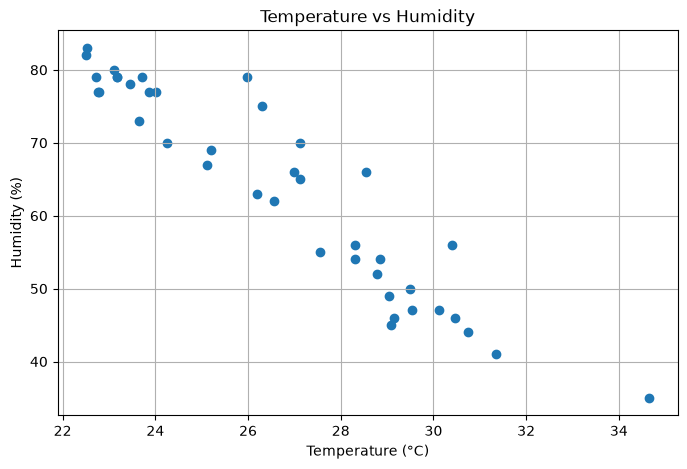

In [46]:
#scatter plot (temp vs humd)
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Temperature'],
    df['Humidity']
)

plt.title('Temperature vs Humidity')
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')

plt.grid()
plt.show()

In [47]:
df.to_csv('weather_data.csv', index=False)

print("Weather data saved successfully!")

Weather data saved successfully!


In [48]:
#final weather report
print("========== WEATHER REPORT ==========")

print("City:", CITY)

print("Average Temperature:",
      round(df['Temperature'].mean(), 2), "°C")

print("Maximum Temperature:",
      df['Temperature'].max(), "°C")

print("Minimum Temperature:",
      df['Temperature'].min(), "°C")

print("Average Humidity:",
      round(df['Humidity'].mean(), 2), "%")

print("Average Wind Speed:",
      round(df['Wind_Speed'].mean(), 2), "m/s")

print("Total Forecast Rainfall:",
      df['Precipitation'].sum(), "mm")

print("Total Forecast Records:", len(df))

========== WEATHER REPORT ==========
City: Pune
Average Temperature: 26.67 °C
Maximum Temperature: 34.66 °C
Minimum Temperature: 22.5 °C
Average Humidity: 63.72 %
Average Wind Speed: 2.2 m/s
Total Forecast Rainfall: 15.39 mm
Total Forecast Records: 40
